# Fitting the Gaia astrometry of a single-planet system

This notebook
1. simulates Gaia DR5 epoch astrometry of a star with one giant planet,
2. fits the orbit (a search over the nonlinear parameters $P$, $\phi_p$, $e$, with the linear parameters solved exactly),
3. plots the orbit on the sky and the along-scan residuals, and
4. samples the posterior with MCMC ([emcee](https://emcee.readthedocs.io)) and shows a corner plot.

It needs `gaiamockplus`, `emcee` and `corner`. The first simulation downloads the Gaia scanning-law data (286 MB, once).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import gaiamockplus as gmp
from gaiamockplus import gaiamock

%config InlineBackend.figure_format = 'retina'

c_funcs = gaiamock.read_in_C_functions()  # compiled functions used by gaiamock's routines
rng = np.random.default_rng(23)           # random numbers for the simulation (reproducible)
M_JUP = 1/1047.57                         # Jupiter mass in Msun

## 1. Simulate the epoch astrometry

A planet is a dict of its orbital elements and mass. As in gaiamock, periods and times are in days ($T_p$ is the time of periastron relative to the reference epoch of the data release), angles are in radians, and masses are in $M_\odot$. $\omega$ is the argument of periastron of the *star's* orbit.

In [2]:
# the star: a 0.8 Msun main-sequence star at 100 pc
m_star = 0.8               # Msun
parallax = 10.0            # mas
phot_g_mean_mag = 11.1     # G magnitude of such a star at 100 pc
ra, dec = 25.0, -13.0      # deg
pmra, pmdec = 12.0, 30.0   # mas/yr

# the planet: 8 Jupiter masses at 4 AU (period from Kepler's third law, neglecting the planet's mass)
planet = dict(period=365.25*4.0**1.5/np.sqrt(m_star), Tp=500.0, ecc=0.2,
              Omega=np.radians(110.0), inc=np.radians(60.0), w=np.radians(50.0), m_planet=8*M_JUP)

data = gmp.predict_astrometry_planets(ra=ra, dec=dec, parallax=parallax, pmra=pmra, pmdec=pmdec, m_star=m_star,
                                      planets=[planet], phot_g_mean_mag=phot_g_mean_mag, data_release='dr5',
                                      c_funcs=c_funcs, rng=rng)
t_ast_yr, psi, plx_factor, ast_obs, ast_err = data  # times (yr), scan angles, parallax factors, along-scan positions and errors (mas)

a0_true = gmp.get_planet_a0_mas(m_star, [planet], parallax)[0]
print(f'{len(t_ast_yr)} field-of-view transits; P = {planet["period"]/365.25:.2f} yr; star\'s reflex semimajor axis '
      f'a0 = {a0_true:.3f} mas; median uncertainty {np.median(ast_err):.3f} mas')

166 field-of-view transits; P = 8.94 yr; star's reflex semimajor axis a0 = 0.379 mas; median uncertainty 0.047 mas


## 2. Fit the orbit

`fit_astrometry_planets` searches for the nonlinear parameters $(P, \phi_p, e)$ with gaiamock's default optimizer (a circular-orbit periodogram, a scan in $e$ and $\phi_p$ at the best periods, and Nelder-Mead polishing). For each trial, the 9 linear parameters are solved exactly by weighted least squares: the position offsets, parallax and proper motion, and the Thiele-Innes elements $A, B, F, G$. The result contains the best-fit parameter vector `theta`, the Campbell elements, the planet mass (given `m_star`), and uncertainties (inflated by `uncertainty_scale`, as in gaiamock).

In [3]:
res = gmp.fit_astrometry_planets(*data, n_planets=1, m_star=m_star)
fit = res['planets'][0]

print(f"chi2 = {res['chi2_history'][0]:.0f} (no planet) -> {res['chi2']:.0f} (one planet) for {res['n_obs']} measurements")
print('best fit:', ', '.join(f'{name} = {value:.4g}' for name, value in zip(res['theta_names'], res['theta'])))

chi2 = 1899 (no planet) -> 170 (one planet) for 166 measurements
best fit: ra_off = -0.005381, dec_off = -0.00344, parallax = 10, pmra = 12, pmdec = 30, period_0 = 3299, ecc_0 = 0.1922, phi_p_0 = 0.8692, A_0 = -0.2237, B_0 = 0.2112, F_0 = -0.03775, G_0 = -0.2967


In [4]:
# compare with the truth
rows = [('parallax [mas]', parallax, res['parallax'], res['sig_parallax']),
        ('P [yr]', planet['period']/365.25, fit['period']/365.25, fit['sig_period']/365.25),
        ('e', planet['ecc'], fit['ecc'], fit['sig_ecc']),
        ('a0 [mas]', a0_true, fit['a0_mas'], fit['sig_a0_mas']),
        ('m_p [M_Jup]', planet['m_planet']/M_JUP, fit['m_planet']/M_JUP, fit['sig_m_planet']/M_JUP),
        ('inc [deg]', 60.0, np.degrees(fit['inc']), np.degrees(fit['sig_inc'])),
        ('w [deg]', 50.0, np.degrees(fit['w']), np.degrees(fit['sig_w'])),
        ('Omega [deg]', 110.0, np.degrees(fit['Omega']), np.degrees(fit['sig_Omega']))]
print(f"{'':15s} {'true':>8s} {'fit':>16s}")
for label, true, value, sigma in rows:
    print(f'{label:15s} {true:8.3f} {value:8.3f} +/- {sigma:.3f}')

                    true              fit
parallax [mas]    10.000   10.002 +/- 0.009
P [yr]             8.944    9.033 +/- 0.148
e                  0.200    0.192 +/- 0.048
a0 [mas]           0.379    0.383 +/- 0.013
m_p [M_Jup]        8.000    8.012 +/- 0.282
inc [deg]         60.000   59.468 +/- 2.026
w [deg]           50.000   43.629 +/- 15.010
Omega [deg]      110.000  110.805 +/- 2.379


Astrometry alone cannot distinguish $(\Omega, \omega)$ from $(\Omega + \pi, \omega + \pi)$, so $\Omega$ is returned in $[0, \pi)$ (radial velocities break this degeneracy).

## 3. The orbit on the sky and the along-scan residuals

Gaia measures only the along-scan coordinate. In the sky plot (gaiamock's `plot_2d_orbit_and_residuals`), each measurement is placed at the best-fit orbit position at that time, offset by its residual along the scan direction (with its error bar along the same direction); the grey square marks periastron. The second figure shows the residuals of the best-fit models without and with the planet.

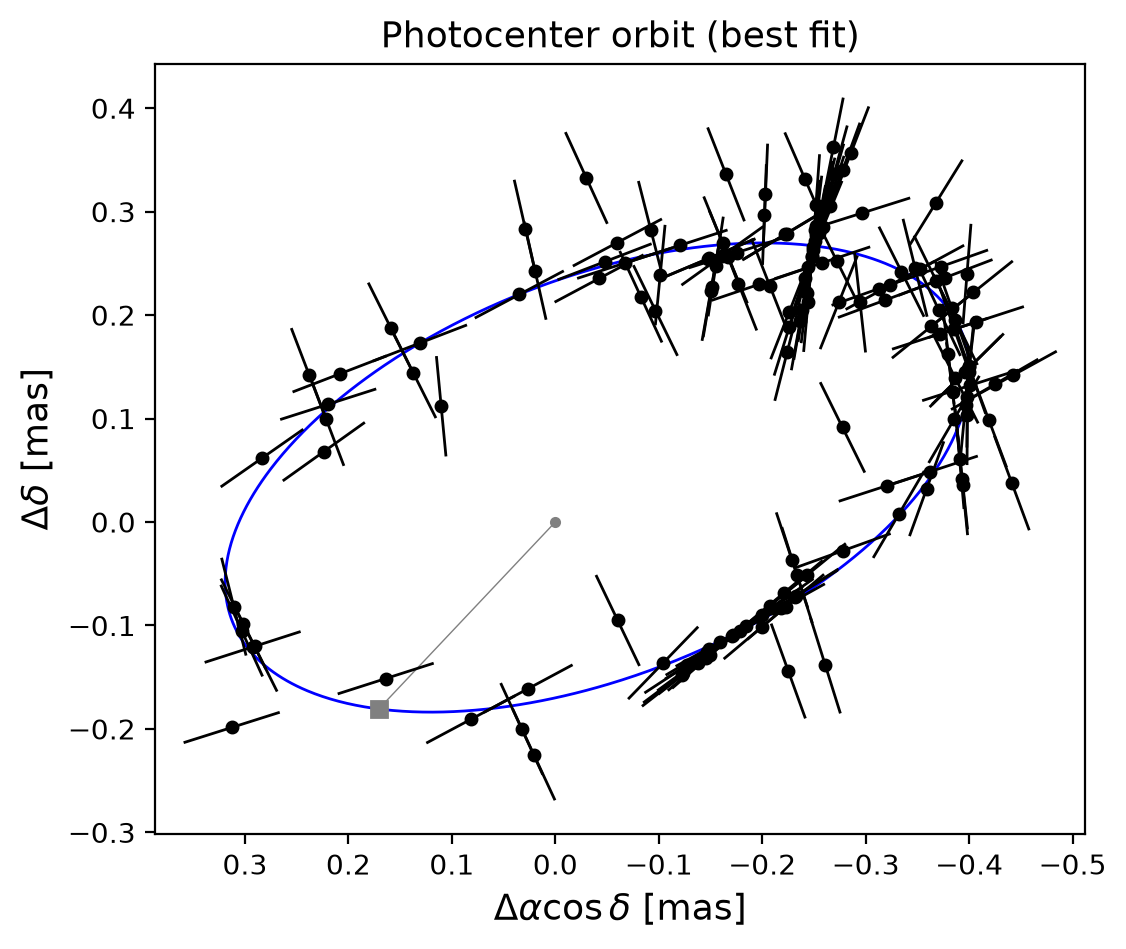

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
gaiamock.plot_2d_orbit_and_residuals(*data, period=fit['period'], ecc=fit['ecc'], Tp=fit['Tp'],
                                     delta_ra=res['ra_off'], delta_dec=res['dec_off'], parallax=res['parallax'],
                                     pmra=res['pmra'], pmdec=res['pmdec'], A=fit['A'], B=fit['B'], F=fit['F'], G=fit['G'],
                                     data_release='dr5', c_funcs=c_funcs, ax=ax)
ax.set_aspect('equal', adjustable='datalim')
ax.set_xlabel(r'$\Delta\alpha\cos\delta$ [mas]', fontsize=13)
ax.set_ylabel(r'$\Delta\delta$ [mas]', fontsize=13)
ax.set_title('Photocenter orbit (best fit)', fontsize=13)
plt.show()

single star chi2: 1898.86
binary star chi2: 169.84


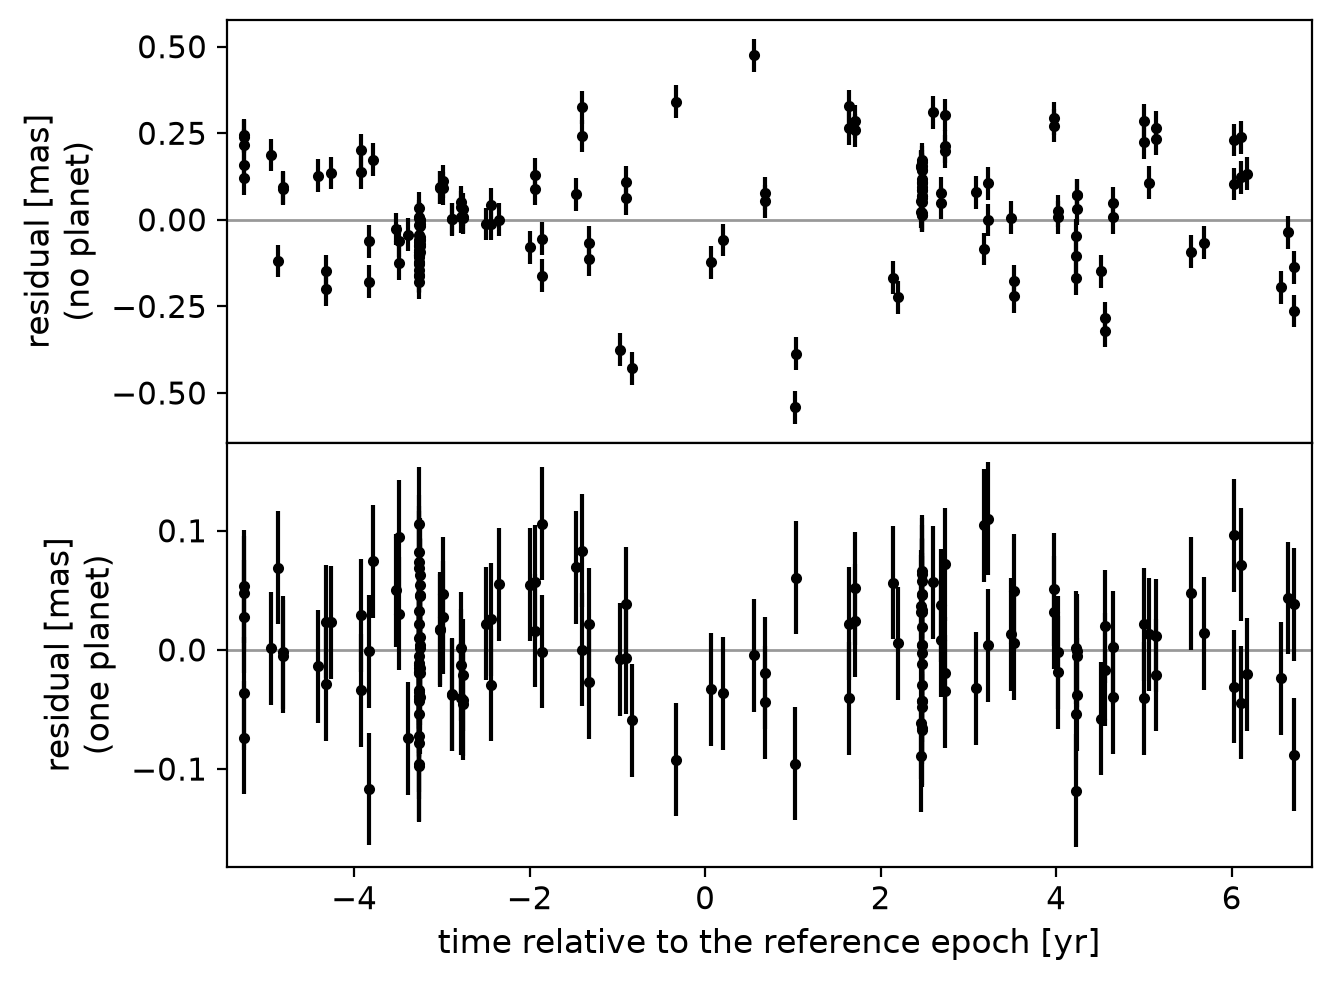

In [6]:
gaiamock.plot_residuals(*data, theta_array=[fit['period'], fit['phi_p'], fit['ecc']], c_funcs=c_funcs)
fig = plt.gcf()
fig.set_size_inches(7, 5.5)
for ax, label in zip(fig.axes, ['no planet', 'one planet']):
    ax.axhline(0, color='0.6', lw=1, zorder=0)
    ax.tick_params(labelsize=11)
    ax.set_ylabel(f'residual [mas]\n({label})', fontsize=12)
fig.axes[-1].set_xlabel('time relative to the reference epoch [yr]', fontsize=12)
plt.show()

## 4. MCMC

The MCMC samples the planet's physical parameters, as the joint fits of notebooks 03 to 06 do, with the same priors, so that astrometry-only and joint results can be compared directly: the parallax, then $P$, $e$, $\phi_p$, $\Omega$, $i$, $\omega$ and $a_0$ (and the jitter below). Without RVs, `fit_astrometry_and_rv_planets` fits the astrometry alone in these parameters (here started from the orbit found above, with `initial_planets`), and `log_likelihood_astrometry_and_rv_planets` evaluates its likelihood. By default, the position offsets and proper motion, on which the model depends linearly, are integrated out of the likelihood analytically, with flat priors, so the walkers sample 9 parameters instead of 13; this gives exactly the posterior of sampling all 13, but the chain converges faster. After the MCMC, `expand_marginal_samples` draws the integrated-out parameters of each sample from their conditional posterior, which is Gaussian.

The model also depends linearly on the Thiele-Innes elements $A$, $B$, $F$, $G$, and `log_likelihood_astrometry_planets` (with `marginalize=True`) integrates them out too, leaving only $P$, $e$ and $\phi_p$ to sample; but it does so with flat priors on $A$, $B$, $F$, $G$, which amount to a prior $\propto a_0^3 \sin^3 i$ on the Campbell elements, which favors large masses and edge-on orbits. Sampling the Campbell elements instead lets the priors be chosen on them.

The priors are uniform, as in notebook 03: $\varpi > 0$, $P$ within the search range, $0 \le e < 1$, $0 \le i \le \pi$ and $a_0 > 0$ (other values describe the same orbits). $\phi_p$ and $\omega$ are kept within $\pi$ of their best-fit values: the likelihood is periodic in them, so these windows contain every orbit exactly once, whereas without them the walkers could drift apart by multiples of $2\pi$, which would stall the chain. $\Omega$ is kept within $\pi/2$ of its best-fit value: with astrometry alone, $(\Omega + \pi, \omega + \pi)$ is an equally good orbit (RVs, as in notebook 03, tell them apart, and the joint fits keep $\Omega$ within $\pi$), so a range of $\pi$ (like gaiamock's $[0, \pi)$) contains every distinct orbit once; the posterior of the other solution is the same, with $\Omega$ and $\omega$ shifted by $\pi$. (With the full range, the walkers can cross slowly between the two solutions through nearly face-on orbits, for which only $\Omega + \omega$ matters.)

The reported uncertainties of Gaia epoch astrometry do not include all of the noise (gaiamock's simulations of stars brighter than G = 13 add unmodeled noise with $\sigma$ drawn from U(0, 0.04) mas). So the likelihood includes an astrometric jitter $s$, added in quadrature to each epoch's uncertainty (`fit_ast_jitter=True`; $s$ is the last parameter, with a uniform prior on [0, 0.5) mas). `estimate_astrometric_jitter` gives its starting value: the jitter that makes the reduced $\chi^2$ of the best fit 1.

`initial_walkers` starts the walkers in a small ball around the best fit, scaled by the fit's uncertainties (and inside the prior), in the sampled parameters (`sampled_names(res_phys)`), with the jitter appended.

In [7]:
# the best fit in the physical parameters of the joint fits (the orbit found above)
res_phys = gmp.fit_astrometry_and_rv_planets(*data, n_planets=1, m_star=m_star, initial_planets=res['planets'])
best = dict(zip(res_phys['theta_names'], res_phys['theta']))  # best-fit values by name
angles0 = np.array([best['phi_p_0'], best['Omega_0'], best['w_0']])
windows = np.array([np.pi, np.pi/2, np.pi])  # phi_p and w within pi of the best fit, Omega within pi/2 (see above)

def log_prior(theta):
    plx, P, e, inc, a0, s = theta[0], theta[1], theta[2], theta[5], theta[7], theta[8]
    angles = theta[[3, 4, 6]]  # phi_p, Omega, w
    if (0 < plx and 10 < P < 1e4 and 0 <= e < 1 and 0 <= inc <= np.pi and 0 < a0 and np.all(np.abs(angles - angles0) < windows)
            and 0 <= s < 0.5):
        return 0.0
    return -np.inf

def log_prob(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + gmp.log_likelihood_astrometry_and_rv_planets(theta, *data, fit_ast_jitter=True)

s0 = gmp.estimate_astrometric_jitter(res_phys, ast_err)
print(f'starting astrometric jitter: {1e3*s0:.1f} microarcsec')
nwalkers, nsteps = 50, 11500
p0 = gmp.initial_walkers(res_phys, nwalkers, log_prob=log_prior, ast_jitter=s0, rng=rng)
np.random.seed(23)  # emcee draws its moves from numpy's global random state
sampler = emcee.EnsembleSampler(nwalkers, p0.shape[1], log_prob)
sampler.run_mcmc(p0, nsteps, progress=True);

starting astrometric jitter: 15.2 microarcsec


In [8]:
# convergence: the chain should be much longer than the autocorrelation time (emcee suggests > 50 times; tol=0: estimate it whatever the chain length)
tau = sampler.get_autocorr_time(tol=0)
print('autocorrelation times [steps]:', ', '.join(f'{n} {t:.0f}' for n, t in zip(gmp.sampled_names(res_phys) + ['ast_jitter'], tau)))
print(f'chain length / longest autocorrelation time = {nsteps/tau.max():.0f}')

# discard the burn-in (5 autocorrelation times) and thin the chain
burn, thin = int(5*tau.max()), int(tau.max()/2)
samples = sampler.get_chain(discard=burn, thin=thin, flat=True)
print(f'{len(samples)} samples after discarding {burn} steps of burn-in and thinning by {thin}')

# draw the position offsets and proper motion of each sample: samples of all parameters, ordered like res_phys['theta'], then the jitter
samples = gmp.expand_marginal_samples(samples, res_phys, ast_data=data, fit_ast_jitter=True, rng=rng)

autocorrelation times [steps]: parallax 104, period_0 102, ecc_0 102, phi_p_0 106, Omega_0 100, inc_0 108, w_0 105, a0_mas_0 105, ast_jitter 107
chain length / longest autocorrelation time = 106
10100 samples after discarding 540 steps of burn-in and thinning by 54


## 5. Corner plot

The planet mass is computed for each sample from $a_0$, $P$, $\varpi$ and the stellar mass (the parallax is shown relative to its best-fit value). The red lines mark the true values (the simulator does not return the value of its unmodeled noise, so the jitter has none).

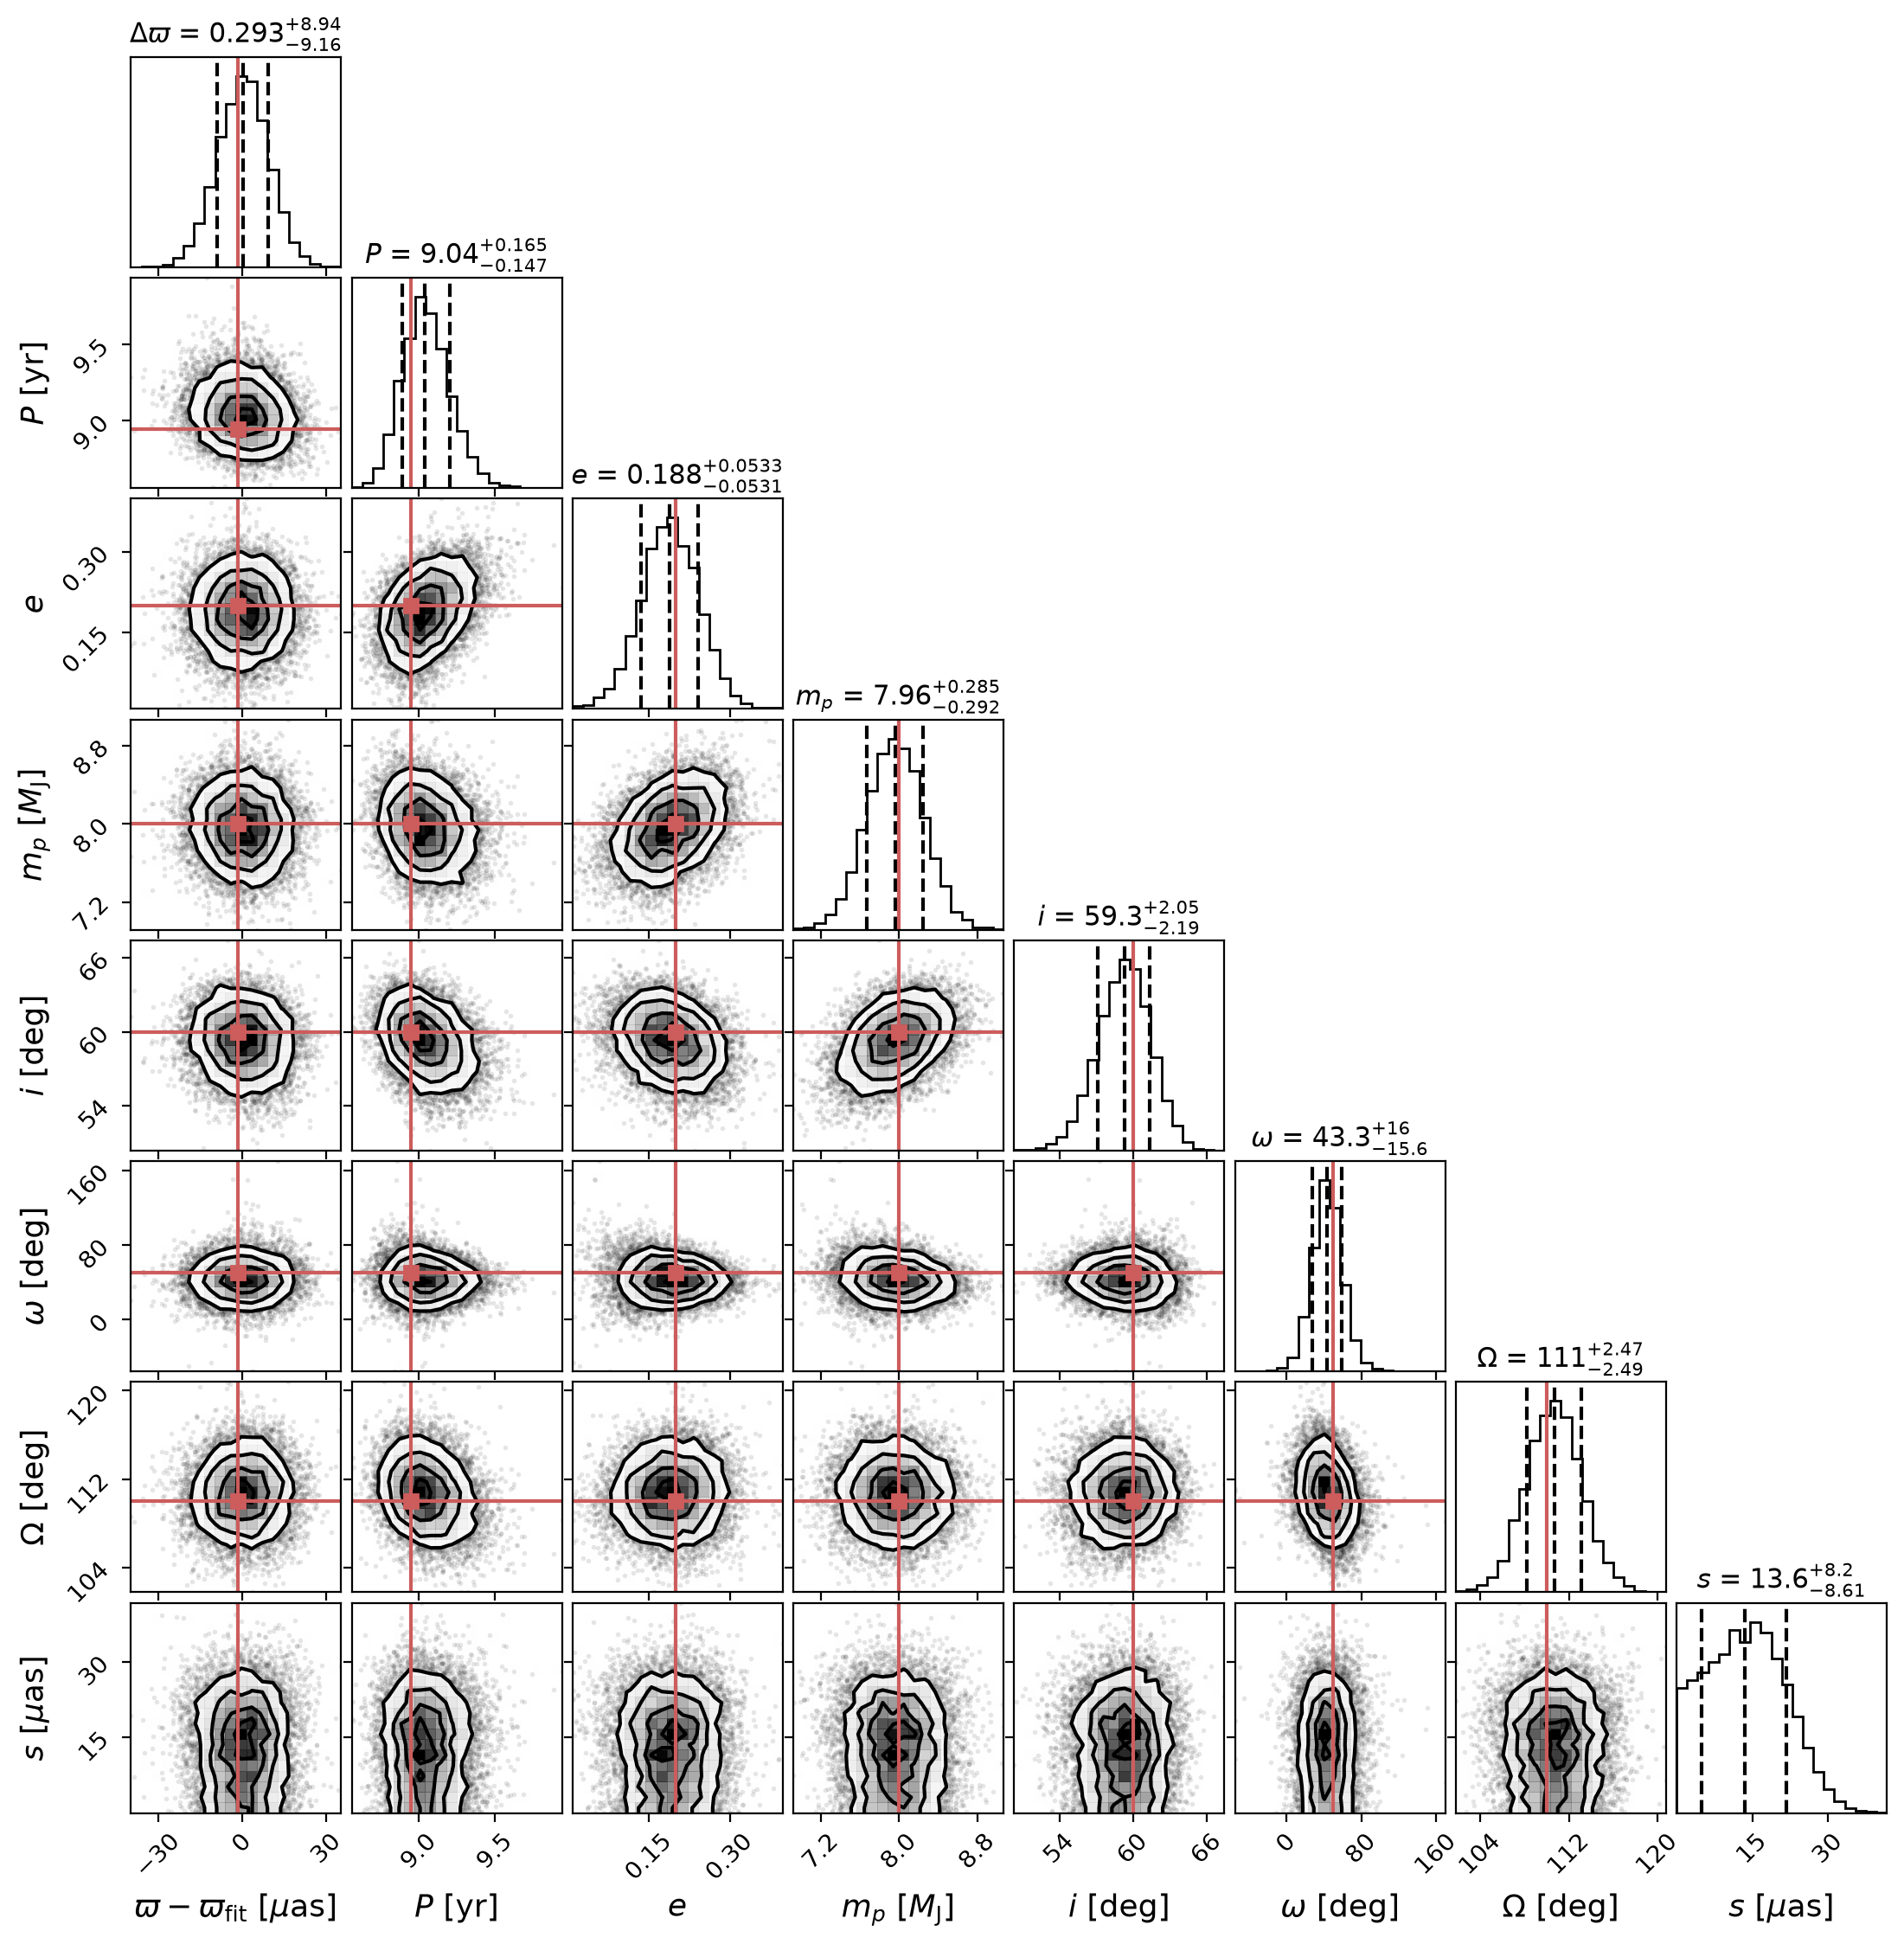

In [9]:
plx_s, P_s, e_s, Omega_s, inc_s, w_s, a0_s = (samples[:, k] for k in (2, 5, 6, 8, 9, 10, 11))
m_s = gmp.get_dark_companion_mass(a0_mas=a0_s, period=P_s, parallax=plx_s, m1=m_star)

corner_samples = np.column_stack([1e3*(plx_s - res['parallax']), P_s/365.25, e_s, m_s/M_JUP, np.degrees(inc_s), np.degrees(w_s), np.degrees(Omega_s),
                                  1e3*samples[:, -1]])
labels = [r'$\varpi - \varpi_\mathrm{fit}$ [$\mu$as]', r'$P$ [yr]', r'$e$', r'$m_p$ [$M_\mathrm{J}$]', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]',
          r'$s$ [$\mu$as]']
truths = [1e3*(parallax - res['parallax']), planet['period']/365.25, planet['ecc'], planet['m_planet']/M_JUP, 60.0, 50.0, 110.0, None]

titles = [r'$\Delta\varpi$', r'$P$', r'$e$', r'$m_p$', r'$i$', r'$\omega$', r'$\Omega$', r'$s$']
fig = corner.corner(corner_samples, labels=labels, titles=titles, truths=truths, truth_color='indianred',
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g', max_n_ticks=3, labelpad=0.08,
                    label_kwargs=dict(fontsize=13), title_kwargs=dict(fontsize=11))
fig.set_size_inches(11, 11)
plt.show()

In [10]:
# the posterior widths agree with the fit's uncertainties (inflated as in gaiamock, rather than with a jitter)
for label, s, sigma_fit in [('P [yr]', P_s/365.25, fit['sig_period']/365.25), ('e', e_s, fit['sig_ecc']),
                            ('m_p [M_Jup]', m_s/M_JUP, fit['sig_m_planet']/M_JUP), ('inc [deg]', np.degrees(inc_s), np.degrees(fit['sig_inc']))]:
    lo, med, hi = np.percentile(s, [16, 50, 84])
    print(f'{label:12s} MCMC {med:.3f} (+{hi - med:.3f} / -{med - lo:.3f});  fit uncertainty {sigma_fit:.3f}')

P [yr]       MCMC 9.039 (+0.165 / -0.147);  fit uncertainty 0.148
e            MCMC 0.188 (+0.053 / -0.053);  fit uncertainty 0.048
m_p [M_Jup]  MCMC 7.960 (+0.285 / -0.292);  fit uncertainty 0.282
inc [deg]    MCMC 59.312 (+2.055 / -2.192);  fit uncertainty 2.026
